# Analisis Social Media
---
## 1. Overview Analisis

1. **Data understanding & cleaning** : cek struktur, nilai kosong, duplikasi
2. **Feature engineering** : metrik engagement, pengelompokan isu tematik
3. **Exploratory analysis** : 5 dimensi: kategori isu, platform, tren waktu, top keyword, top akun
4. **Teks Analysis** : Sentiment Analysis
4. **Insight & rekomendasi**


## 3. Setup & Load Data

In [1]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from collections import Counter, defaultdict

plt.rcParams['figure.dpi'] = 110
plt.rcParams['font.size'] = 10
pd.set_option('display.max_columns', None)

In [2]:
FILE_NAME = "/content/Data Test_Assigment Tahap 1.xlsx"
df_raw = pd.read_excel(FILE_NAME, sheet_name="Posts")
print("Jumlah baris:", df_raw.shape[0], "| Jumlah kolom:", df_raw.shape[1])
df_raw.head(3)

Jumlah baris: 15134 | Jumlah kolom: 28


,project_id,keyword,nama_akun,kandidat,wilayah,parent_link,tanggal_post,jumlah_komentar,jumlah_like,jumlah_share,jumlah_view,media_type,jenis_akun,klasifikasi_isu,topik,sentimen,text,clean_text,tanggal_crawling,created_at,updated_at,jumlah_reach,engagement,batch_id,community,top_bigrams,confidence,id
0,146,pemerintah,inilahcom,NaN,NaN,https://www.tiktok.com/@inilahcom/video/763449...,2026-04-30 17:02:47,99,4695.0,40,473897,Tiktok,NaN,NaN,NaN,NaN,Tragedi tabrakan kereta di Bekasi bukan sekada...,NaN,NaN,2026-05-01 00:17:55,2026-05-01 00:17:55,473897,4834,26-05-01_00:17,NaN,NaN,NaN,306131
1,146,pemerintah,metro_tv,NaN,NaN,https://www.tiktok.com/@metro_tv/video/7634488...,2026-04-30 16:53:14,7,433.0,4,30100,Tiktok,NaN,NaN,NaN,NaN,Di tengah eskalasi konflik regional di kawasan...,NaN,NaN,2026-05-01 00:17:55,2026-05-01 00:17:55,30100,444,26-05-01_00:17,NaN,NaN,NaN,306132
2,146,pemerintah,beritasatuofficial,NaN,NaN,https://www.tiktok.com/@beritasatuofficial/vid...,2026-04-30 16:15:26,52,784.0,57,60432,Tiktok,NaN,NaN,NaN,NaN,Pemerintah melalui Kementerian Komunikasi dan ...,NaN,NaN,2026-05-01 00:17:55,2026-05-01 00:17:55,60432,893,26-05-01_00:17,NaN,NaN,NaN,306133


## 4. Data Understanding

Cek tipe data dan proporsi nilai kosong pada tiap kolom untuk menentukan kolom mana yang bisa dipakai.

In [3]:
df_raw.info()
display(df_raw.describe(include="all").T)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15134 entries, 0 to 15133
Data columns (total 28 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   project_id        15134 non-null  int64         
 1   keyword           15134 non-null  object        
 2   nama_akun         14690 non-null  object        
 3   kandidat          0 non-null      float64       
 4   wilayah           0 non-null      float64       
 5   parent_link       15134 non-null  object        
 6   tanggal_post      15134 non-null  datetime64[ns]
 7   jumlah_komentar   15134 non-null  int64         
 8   jumlah_like       14841 non-null  float64       
 9   jumlah_share      15134 non-null  int64         
 10  jumlah_view       15134 non-null  int64         
 11  media_type        15134 non-null  object        
 12  jenis_akun        0 non-null      float64       
 13  klasifikasi_isu   0 non-null      float64       
 14  topik             0 no

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
project_id,15134.0,NaN,NaN,NaN,146.0,146.0,146.0,146.0,146.0,146.0,0.0
keyword,15134,54,prabowo,1564,NaN,NaN,NaN,NaN,NaN,NaN,NaN
nama_akun,14690,8560,gimsamarketler,86,NaN,NaN,NaN,NaN,NaN,NaN,NaN
kandidat,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
wilayah,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
parent_link,15134,14294,https://www.tiktok.com/@sindonews/video/763301...,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tanggal_post,15134,NaN,NaN,NaN,2026-04-29 11:07:30.614510336,2026-04-23 19:05:56,2026-04-28 11:36:44.500000,2026-04-29 17:21:11,2026-04-30 15:15:39.750000128,2026-05-01 04:32:40,NaN
jumlah_komentar,15134.0,NaN,NaN,NaN,42.23847,0.0,0.0,0.0,2.0,22587.0,397.021947
jumlah_like,14841.0,NaN,NaN,NaN,635.979853,0.0,0.0,3.0,25.0,608949.0,8882.554259
jumlah_share,15134.0,NaN,NaN,NaN,58.603674,0.0,0.0,0.0,3.0,80403.0,1210.815074


In [4]:
missing = df_raw.isnull().sum().sort_values(ascending=False)
missing_pct = (missing / len(df_raw) * 100).round(1)
pd.DataFrame({'missing_count': missing, 'missing_pct': missing_pct})

,missing_count,missing_pct
kandidat,15134,100.0
wilayah,15134,100.0
klasifikasi_isu,15134,100.0
community,15134,100.0
top_bigrams,15134,100.0
confidence,15134,100.0
tanggal_crawling,15134,100.0
clean_text,15134,100.0
sentimen,15134,100.0
topik,15134,100.0


**Cek lanjutan:** beberapa kolom numerik (`jumlah_like`, `jumlah_view`) tidak tercatat sebagai "missing" oleh `isnull()` karena terisi 0, bukan `NaN` — padahal 0 di sini bisa berarti dua hal berbeda: (a) post memang tidak ditonton, atau (b) platform tidak menyediakan data tersebut sama sekali. Untuk membedakannya, dicek proporsi nilai 0 per platform:

In [5]:
view_check = df_raw.groupby('media_type')['jumlah_view'].agg(
    jumlah_post='count',
    post_dengan_view_lebih_dari_0=lambda x: (x > 0).sum(),
).assign(persen_view_nol=lambda d: ((d['jumlah_post'] - d['post_dengan_view_lebih_dari_0']) / d['jumlah_post'] * 100).round(1))
view_check

,jumlah_post,post_dengan_view_lebih_dari_0,persen_view_nol
media_type,,,
Facebook,2806,2802,0.1
Instagram,10573,17,99.8
Tiktok,1755,1755,0.0


In [6]:
# 1. Pilih hanya kolom numerik (int64 & float64)
num_cols = df_raw.select_dtypes(include=['int64', 'float64']).columns

# 2. Buat tabel pengecekan nilai 0
zero_check = pd.DataFrame({
    'jumlah_post': df_raw[num_cols].count(),
    'post_dengan_nilai_lebih_dari_0': (df_raw[num_cols] > 0).sum(),
    'jumlah_nilai_nol': (df_raw[num_cols] == 0).sum(),
    'persen_nilai_nol': ((df_raw[num_cols] == 0).sum() / df_raw[num_cols].count() * 100).round(1)
})

zero_check

,jumlah_post,post_dengan_nilai_lebih_dari_0,jumlah_nilai_nol,persen_nilai_nol
project_id,15134,15134,0,0.0
kandidat,0,0,0,NaN
wilayah,0,0,0,NaN
jumlah_komentar,15134,5368,9766,64.5
jumlah_like,14841,10696,4145,27.9
jumlah_share,15134,5297,9837,65.0
jumlah_view,15134,4574,10560,69.8
jenis_akun,0,0,0,NaN
klasifikasi_isu,0,0,0,NaN
topik,0,0,0,NaN


In [7]:
# 1. Ambil nama kolom numerik (keluarkan 'media_type' dari pendaftaran numerik jika ada)
num_cols = df_raw.select_dtypes(include=['int64', 'float64']).columns.tolist()

# 2. Groupby media_type dan hitung persentase nilai 0 per kolom
zero_check_by_media = df_raw.groupby('media_type')[num_cols].apply(
    lambda g: (g == 0).mean().mul(100).round(1)
).add_suffix('_persen_nol')

zero_check_by_media

,project_id_persen_nol,kandidat_persen_nol,wilayah_persen_nol,jumlah_komentar_persen_nol,jumlah_like_persen_nol,jumlah_share_persen_nol,jumlah_view_persen_nol,jenis_akun_persen_nol,klasifikasi_isu_persen_nol,topik_persen_nol,sentimen_persen_nol,clean_text_persen_nol,tanggal_crawling_persen_nol,jumlah_reach_persen_nol,engagement_persen_nol,community_persen_nol,top_bigrams_persen_nol,confidence_persen_nol,id_persen_nol
media_type,,,,,,,,,,,,,,,,,,,
Facebook,0.0,0.0,0.0,31.5,0.2,59.1,0.1,0.0,0.0,0.0,0.0,0.0,0.0,0.1,0.1,0.0,0.0,0.0,0.0
Instagram,0.0,0.0,0.0,80.6,39.0,72.9,99.8,0.0,0.0,0.0,0.0,0.0,0.0,99.8,33.3,0.0,0.0,0.0,0.0
Tiktok,0.0,0.0,0.0,20.5,1.0,26.6,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0


**Temuan data quality:**
- 11 kolom **100% kosong** (`kandidat`, `wilayah`, `jenis_akun`, `klasifikasi_isu`, `topik`, `sentimen`, `clean_text`, `tanggal_crawling`, `community`, `top_bigrams`, `confidence`)
- `nama_akun` kosong pada 444 baris, `jumlah_like` kosong pada 293 baris, `text` kosong pada 7 baris — jumlahnya kecil (<3%), ditangani dengan imputasi/pengabaian saat relevan, bukan drop massal
- `jumlah_view` pada Instagram **hampir seluruhnya bernilai 0** (data tidak tersedia dari platform, bukan post tanpa penonton) — sehingga metrik *engagement rate berbasis view* tidak dapat dibandingkan lintas platform secara adil
- Ditemukan 840 `parent_link` duplikat

## 5. Data Cleaning

In [8]:
cols_to_drop = ['kandidat','wilayah','jenis_akun','klasifikasi_isu','topik','sentimen',
                'clean_text','tanggal_crawling','community','top_bigrams','confidence']
df = df_raw.drop(columns=cols_to_drop).copy()

# Normalisasi keyword: hilangkan '#', lowercase, trim -> supaya '#BBM' & 'BBM' terhitung sebagai isu yang sama
df['keyword_clean'] = df['keyword'].str.lower().str.replace('#', '', regex=False).str.strip()

# Isi jumlah_like kosong dengan 0 (asumsi: tidak tercatat = 0 like saat crawling)
df['jumlah_like'] = df['jumlah_like'].fillna(0)

print("Duplikat id:", df['id'].duplicated().sum())
print("Jumlah keyword unik setelah normalisasi:", df['keyword_clean'].nunique(), "(sebelumnya:", df['keyword'].nunique(), ")")

Duplikat id: 0
Jumlah keyword unik setelah normalisasi: 35 (sebelumnya: 54 )


## 6. Feature Engineering

### 6.1 Metrik engagement
`total_engagement = jumlah_like + jumlah_komentar + jumlah_share`

Engagement berbasis *`View`* dihindari karena akan membiaskan kesimpulan akibat kegagalan ekstraksi data view khusus pada platform Instagram

### 6.2 Pengelompokan isu tematik keyword
`reduksi dimensi` melalui Heuristic Categorization (Pengelompokan Tematik) berdasarkan konteks dan kemiripan substansi isu

In [9]:
# Mendapatkan list 35 keyword unik terurut abjad
unique_keywords = sorted(df['keyword_clean'].unique().tolist())

print(f"Total Keyword Unik ({len(unique_keywords)}):")
print(unique_keywords)

Total Keyword Unik (35):
['air keras', 'ambang batas parlemen', 'bansos', 'bbm', 'board of peace', 'cadangan', 'defisit', 'food estate', 'gibran', 'guru', 'ijazah jokowi', 'ikn', 'impeachment', 'kdmp', 'ketahanan pangan', 'knmp', 'kopdes', 'koperasi desa merah putih', 'korupsi', 'mbg', 'minyak', 'no king', 'pekerja', 'pemerintah', 'pemilu 2029', 'pilkada', 'plastik', 'politik', 'polri', 'prabowo', 'prabowo gibran', 'saiful mujani', 'sembako', 'seskab', 'tni']


In [10]:
df['total_engagement'] = df['jumlah_like'] + df['jumlah_komentar'] + df['jumlah_share']

topic_map = {
    'prabowo':'Politik & Pemerintahan','gibran':'Politik & Pemerintahan','prabowo gibran':'Politik & Pemerintahan',
    'ijazah jokowi':'Politik & Pemerintahan','no king':'Politik & Pemerintahan','board of peace':'Politik & Pemerintahan',
    'impeachment':'Politik & Pemerintahan','seskab':'Politik & Pemerintahan','saiful mujani':'Politik & Pemerintahan',
    'ambang batas parlemen':'Politik & Pemerintahan','pemilu 2029':'Politik & Pemerintahan','pilkada':'Politik & Pemerintahan',
    'politik':'Politik & Pemerintahan','pemerintah':'Politik & Pemerintahan',
    'tni':'Keamanan & Pertahanan','polri':'Keamanan & Pertahanan',
    'mbg':'Program Pemerintah','bansos':'Program Pemerintah','sembako':'Program Pemerintah',
    'ketahanan pangan':'Program Pemerintah','food estate':'Program Pemerintah','kopdes':'Program Pemerintah',
    'kdmp':'Program Pemerintah','koperasi desa merah putih':'Program Pemerintah','knmp':'Program Pemerintah',
    'bbm':'Energi & Ekonomi','minyak':'Energi & Ekonomi','plastik':'Energi & Ekonomi',
    'cadangan':'Energi & Ekonomi','defisit':'Energi & Ekonomi',
    'guru':'Ketenagakerjaan & Pendidikan','pekerja':'Ketenagakerjaan & Pendidikan',
    'korupsi':'Hukum & Ketertiban','air keras':'Hukum & Ketertiban',
    'ikn':'Pembangunan (IKN)',
}
df['topic_group'] = df['keyword_clean'].map(topic_map)
assert df['topic_group'].isnull().sum() == 0, "Ada keyword yang belum terpetakan"

df['tanggal'] = df['tanggal_post'].dt.date
df['jam'] = df['tanggal_post'].dt.hour
df.head(3)

,project_id,keyword,nama_akun,parent_link,tanggal_post,jumlah_komentar,jumlah_like,jumlah_share,jumlah_view,media_type,text,created_at,updated_at,jumlah_reach,engagement,batch_id,id,keyword_clean,total_engagement,topic_group,tanggal,jam
0,146,pemerintah,inilahcom,https://www.tiktok.com/@inilahcom/video/763449...,2026-04-30 17:02:47,99,4695.0,40,473897,Tiktok,Tragedi tabrakan kereta di Bekasi bukan sekada...,2026-05-01 00:17:55,2026-05-01 00:17:55,473897,4834,26-05-01_00:17,306131,pemerintah,4834.0,Politik & Pemerintahan,2026-04-30,17
1,146,pemerintah,metro_tv,https://www.tiktok.com/@metro_tv/video/7634488...,2026-04-30 16:53:14,7,433.0,4,30100,Tiktok,Di tengah eskalasi konflik regional di kawasan...,2026-05-01 00:17:55,2026-05-01 00:17:55,30100,444,26-05-01_00:17,306132,pemerintah,444.0,Politik & Pemerintahan,2026-04-30,16
2,146,pemerintah,beritasatuofficial,https://www.tiktok.com/@beritasatuofficial/vid...,2026-04-30 16:15:26,52,784.0,57,60432,Tiktok,Pemerintah melalui Kementerian Komunikasi dan ...,2026-05-01 00:17:55,2026-05-01 00:17:55,60432,893,26-05-01_00:17,306133,pemerintah,893.0,Politik & Pemerintahan,2026-04-30,16


## 7. Exploratory Data Analysis

### 7.1 Isu mana yang paling dominan? (volume vs. engagement)

In [11]:
agg_topic = (df.groupby('topic_group')
             .agg(jumlah_post=('id','count'),
                  total_engagement=('total_engagement','sum'),
                  rata2_engagement=('total_engagement','mean'),
                  total_reach=('jumlah_reach','sum'))
             .sort_values('total_engagement', ascending=False))
agg_topic

,jumlah_post,total_engagement,rata2_engagement,total_reach
topic_group,,,,
Politik & Pemerintahan,4980,6386236.0,1282.376707,108039546
Program Pemerintah,3188,1488384.0,466.870765,24292154
Ketenagakerjaan & Pendidikan,1693,1104472.0,652.375665,18249195
Hukum & Ketertiban,583,889221.0,1525.250429,21267617
Keamanan & Pertahanan,2800,507320.0,181.185714,12293463
Energi & Ekonomi,1527,459367.0,300.829731,8692432
Pembangunan (IKN),363,129722.0,357.360882,1555201


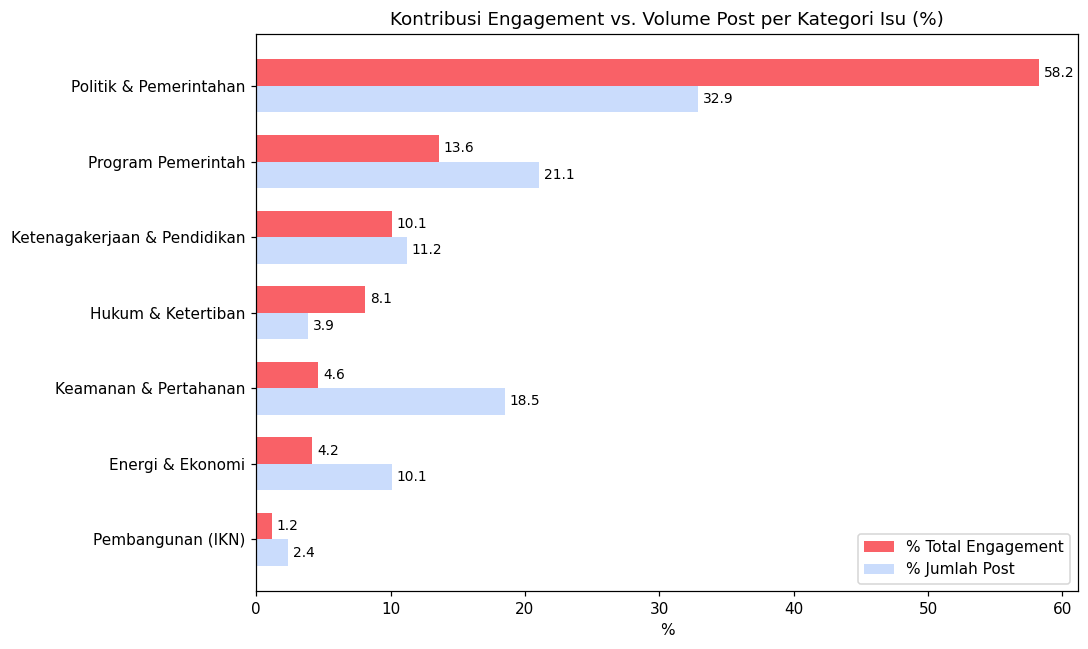

In [12]:
agg_topic['post_pct'] = (agg_topic['jumlah_post'] / agg_topic['jumlah_post'].sum() * 100)
agg_topic['eng_pct'] = (agg_topic['total_engagement'] / agg_topic['total_engagement'].sum() * 100)

order = agg_topic.index[::-1]  # urutan dari bawah ke atas untuk barh
y = np.arange(len(order))
h = 0.35

fig, ax = plt.subplots(figsize=(10, 6))
bars_eng = ax.barh(y + h/2, agg_topic.loc[order, 'eng_pct'], h, label='% Total Engagement', color='#F96167')
bars_post = ax.barh(y - h/2, agg_topic.loc[order, 'post_pct'], h, label='% Jumlah Post', color='#CADCFC')

ax.set_yticks(y)
ax.set_yticklabels(order)
ax.set_xlabel('%')
ax.set_title('Kontribusi Engagement vs. Volume Post per Kategori Isu (%)')
ax.legend(loc='lower right')
ax.bar_label(bars_eng, fmt='%.1f', padding=3, fontsize=9)
ax.bar_label(bars_post, fmt='%.1f', padding=3, fontsize=9)

plt.tight_layout()
plt.savefig('chart_topic_group.png', bbox_inches='tight')
plt.show()

### 7.2 Platform mana yang paling efektif?

In [13]:
agg_platform = (df.groupby('media_type')
                .agg(jumlah_post=('id','count'),
                     total_engagement=('total_engagement','sum'),
                     rata2_engagement=('total_engagement','mean'),
                     total_reach=('jumlah_reach','sum'))
                .sort_values('total_engagement', ascending=False))
agg_platform['share_post_%'] = (agg_platform['jumlah_post']/agg_platform['jumlah_post'].sum()*100).round(1)
agg_platform['share_engagement_%'] = (agg_platform['total_engagement']/agg_platform['total_engagement'].sum()*100).round(1)
agg_platform

,jumlah_post,total_engagement,rata2_engagement,total_reach,share_post_%,share_engagement_%
media_type,,,,,,
Tiktok,1755,8706039.0,4960.705983,172267422,11.6,79.4
Instagram,10573,1174218.0,111.058167,370,69.9,10.7
Facebook,2806,1084465.0,386.480756,22121816,18.5,9.9


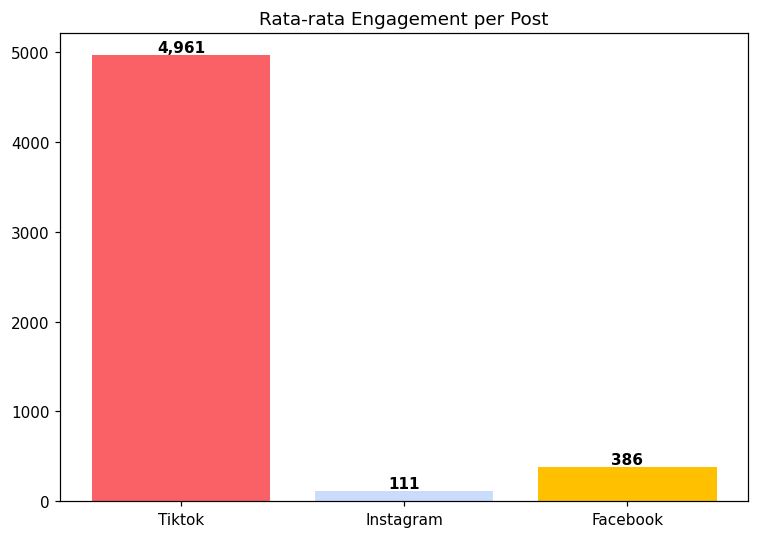

In [32]:
fig, ax = plt.subplots(figsize=(7,5))
colors = {'Tiktok':'#F96167','Instagram':'#CADCFC','Facebook':'#FFC000'}
bars = ax.bar(agg_platform.index, agg_platform['rata2_engagement'],
              color=[colors.get(p,'#888') for p in agg_platform.index])
ax.set_title('Rata-rata Engagement per Post')
for b in bars:
    ax.annotate(f'{b.get_height():,.0f}', (b.get_x()+b.get_width()/2, b.get_height()),
                ha='center', va='bottom', fontsize=10, fontweight='bold')
plt.tight_layout()
plt.savefig('chart_platform.png', bbox_inches='tight')
plt.show()

### 7.3 Kapan lonjakan percakapan terjadi? (tren harian)

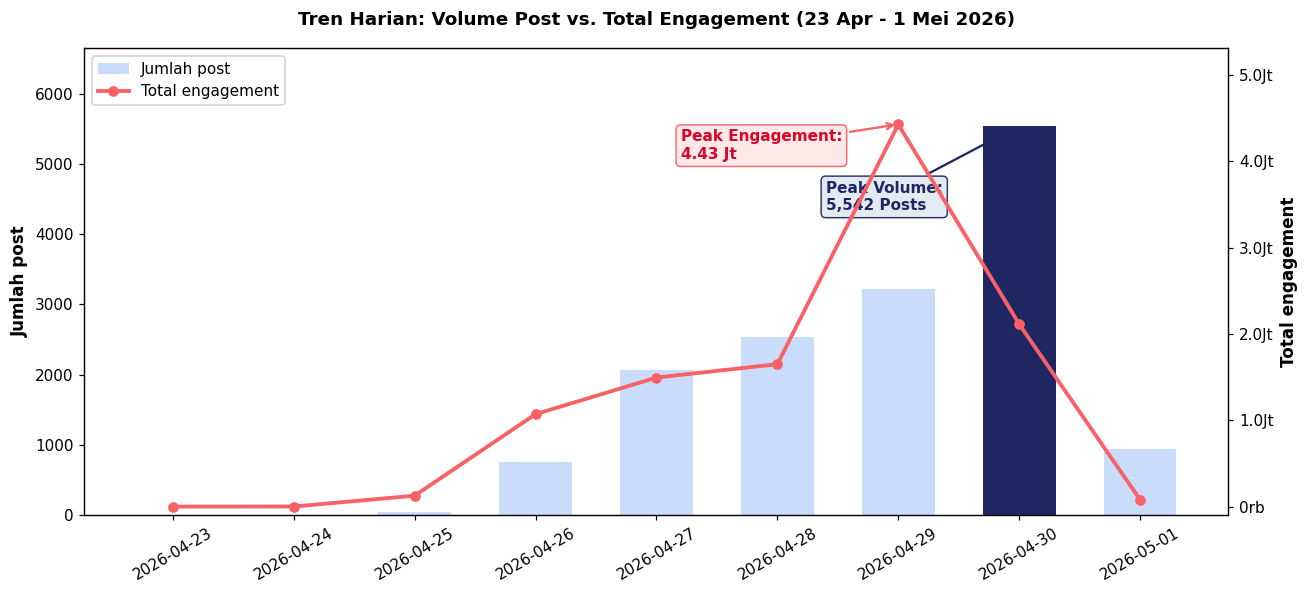

In [15]:
daily = df.groupby('tanggal').agg(jumlah_post=('id','count'), total_engagement=('total_engagement','sum'))

fig, ax1 = plt.subplots(figsize=(12, 5.5))
ax2 = ax1.twinx()

# 1. Cari indeks nilai puncak
max_post_idx = daily['jumlah_post'].idxmax()
max_eng_idx = daily['total_engagement'].idxmax()

# 2. Highlight warna bar (Warna gelap untuk volume terbanyak)
bar_colors = ['#1E2761' if date_idx == max_post_idx else '#CADCFC' for date_idx in daily.index]

# 3. Plot Bar dan Line
bars = ax1.bar(daily.index.astype(str), daily['jumlah_post'], color=bar_colors, width=0.6, label='Jumlah post')
line = ax2.plot(daily.index.astype(str), daily['total_engagement'], color='#F96167', marker='o', linewidth=2.5, label='Total engagement')

# 4. Highlight & Label Puncak Engagement
peak_eng_val = daily.loc[max_eng_idx, 'total_engagement']
ax2.annotate(f'Peak Engagement:\n{peak_eng_val/1e6:.2f} Jt',
             xy=(str(max_eng_idx), peak_eng_val),
             xytext=(daily.index.get_loc(max_eng_idx) - 1.8, peak_eng_val - 400000),
             arrowprops=dict(facecolor='#F96167', edgecolor='#F96167', arrowstyle='->', lw=1.5),
             fontsize=10, fontweight='bold', color='#D90429',
             bbox=dict(boxstyle='round,pad=0.3', facecolor='#FFE6E6', edgecolor='#F96167', alpha=0.9))

# 5. Highlight & Label Puncak Volume Post
peak_post_val = daily.loc[max_post_idx, 'jumlah_post']
ax1.annotate(f'Peak Volume:\n{peak_post_val:,} Posts',
             xy=(str(max_post_idx), peak_post_val),
             xytext=(daily.index.get_loc(max_post_idx) - 1.6, peak_post_val - 1200),
             arrowprops=dict(facecolor='#1E2761', edgecolor='#1E2761', arrowstyle='->', lw=1.5),
             fontsize=10, fontweight='bold', color='#1E2761',
             bbox=dict(boxstyle='round,pad=0.3', facecolor='#E2E8F0', edgecolor='#1E2761', alpha=0.9))

# Formatting
ax1.set_ylabel('Jumlah post', fontsize=11, fontweight='bold')
ax2.set_ylabel('Total engagement', fontsize=11, fontweight='bold')
ax1.set_title('Tren Harian: Volume Post vs. Total Engagement (23 Apr - 1 Mei 2026)', fontsize=12, fontweight='bold', pad=15)

ax1.tick_params(axis='x', rotation=30)
ax2.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x/1e6:.1f}Jt' if x>=1e6 else f'{x/1e3:.0f}rb'))

ax1.set_ylim(0, daily['jumlah_post'].max() * 1.2)
ax2.set_ylim(-100000, daily['total_engagement'].max() * 1.2)

# Single Legend
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left', frameon=True, facecolor='white', framealpha=0.9)

plt.tight_layout()
plt.savefig('chart_trend.png', bbox_inches='tight')
plt.show()

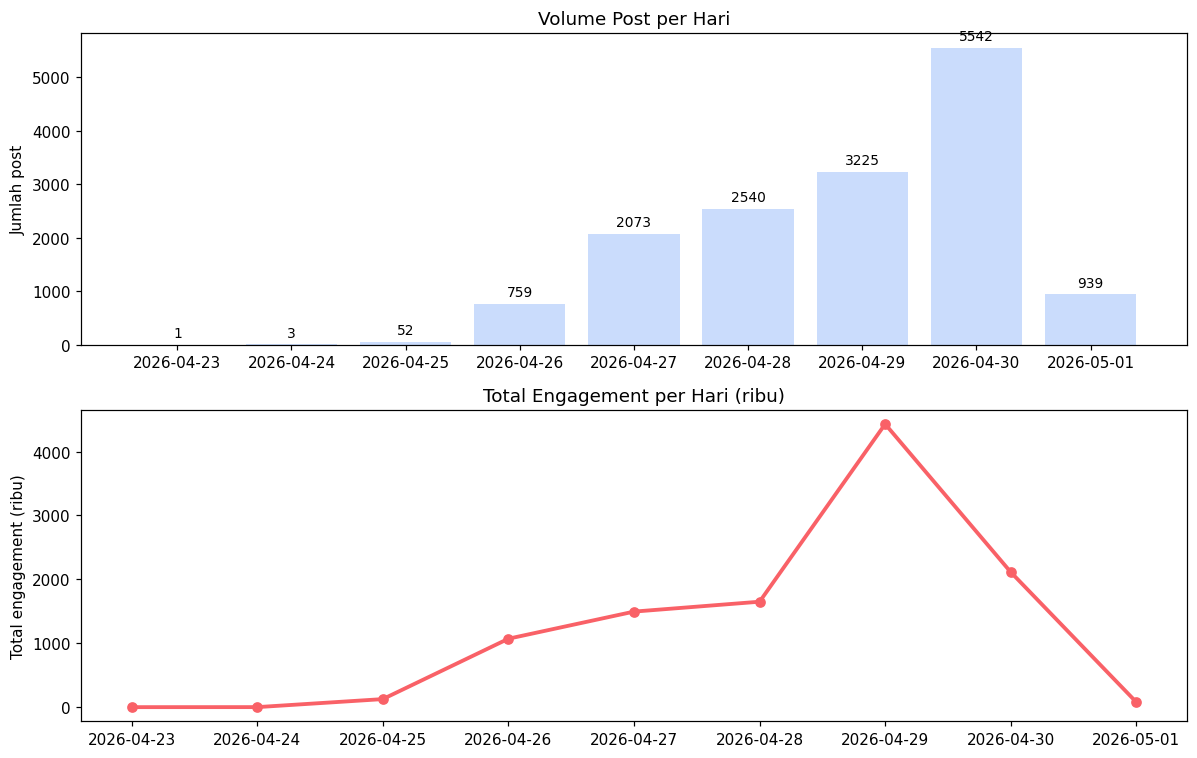

In [33]:
daily = df.groupby('tanggal').agg(jumlah_post=('id','count'), total_engagement=('total_engagement','sum'))
daily['total_engagement_ribu'] = daily['total_engagement'] / 1000

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 7))

bars = ax1.bar(daily.index.astype(str), daily['jumlah_post'], color='#CADCFC')
ax1.set_title('Volume Post per Hari')
ax1.set_ylabel('Jumlah post')
ax1.bar_label(bars, fmt='%.0f', padding=3, fontsize=9)

ax2.plot(daily.index.astype(str), daily['total_engagement_ribu'], color='#F96167', marker='o', linewidth=2.5)
ax2.set_title('Total Engagement per Hari (ribu)')
ax2.set_ylabel('Total engagement (ribu)')

plt.tight_layout()
plt.savefig('chart_trend.png', bbox_inches='tight')
plt.show()

### 7.4 Keyword spesifik apa yang paling viral?

In [17]:
top_keyword = (df.groupby('keyword_clean')
               .agg(jumlah_post=('id','count'), total_engagement=('total_engagement','sum'),
                    rata2_engagement=('total_engagement','mean'))
               .sort_values('total_engagement', ascending=False).head(10))
top_keyword

,jumlah_post,total_engagement,rata2_engagement
keyword_clean,,,
prabowo,1584,1603626.0,1012.390152
politik,1436,1387308.0,966.091922
guru,1483,1068081.0,720.216453
impeachment,411,840212.0,2044.311436
gibran,204,805771.0,3949.857843
no king,98,749840.0,7651.428571
korupsi,429,552104.0,1286.955711
mbg,1483,492457.0,332.068105
pemerintah,452,456250.0,1009.402655


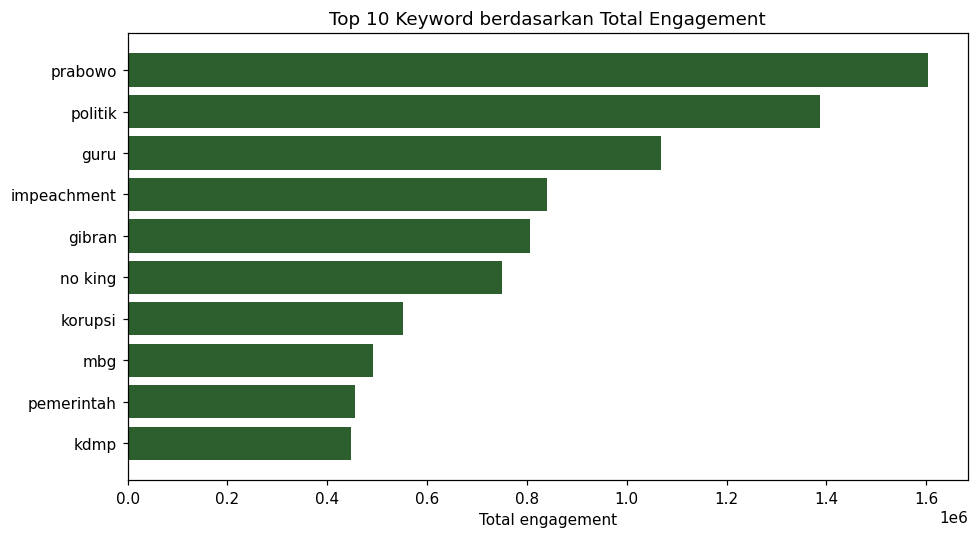

In [18]:
fig, ax = plt.subplots(figsize=(9,5))
ax.barh(top_keyword.index[::-1], top_keyword['total_engagement'][::-1], color='#2C5F2D')
ax.set_title('Top 10 Keyword berdasarkan Total Engagement')
ax.set_xlabel('Total engagement')
plt.tight_layout()
plt.savefig('chart_top_keyword.png', bbox_inches='tight')
plt.show()

### 7.5 Akun mana yang paling berperan menyebarkan isu? (top amplifier)

In [19]:
top_akun = (df.groupby('nama_akun')
            .agg(jumlah_post=('id','count'), total_reach=('jumlah_reach','sum'),
                 total_engagement=('total_engagement','sum'),
                 platform_utama=('media_type', lambda x: x.mode()[0]))
            .sort_values('total_reach', ascending=False).head(10))
top_akun

,jumlah_post,total_reach,total_engagement,platform_utama
nama_akun,,,,
itvpolitics,2,7871167,390233.0,Tiktok
officiallambeturah,5,7744927,236978.0,Tiktok
inilahcom,6,6281429,121089.0,Tiktok
radar_cianjur,1,4476890,143158.0,Tiktok
gmanews,12,4235666,127540.0,Tiktok
metro_tv,28,3702996,96633.0,Tiktok
news5everywhere,13,3695092,84110.0,Tiktok
News5,4,3610410,176981.0,Facebook
dailymail,1,3464332,286463.0,Tiktok


### 7.6 Analisis Teks — Kata Kunci Dominan per Kategori Isu

In [20]:
stopwords = set(open('stopwordbahasa.txt', encoding='utf-8').read().split())

def clean_text_basic(t):
    t = re.sub(r'http\S+', ' ', t)
    t = re.sub(r'#\w+', ' ', t)
    t = re.sub(r'[^a-zA-Z\s]', ' ', t.lower())
    return re.sub(r'\s+', ' ', t).strip()

def tokenize(t):
    words = clean_text_basic(t).split()
    return [w for w in words if len(w) > 3 and w not in stopwords]

df['text'] = df['text'].fillna('')
df['tokens'] = df['text'].apply(tokenize)

for grp in df['topic_group'].unique():
    toks = [w for row in df.loc[df['topic_group']==grp, 'tokens'] for w in row]
    top6 = Counter(toks).most_common(6)
    print(f"{grp:32s} -> {top6}")

Politik & Pemerintahan           -> [('prabowo', 1861), ('presiden', 1456), ('indonesia', 1360), ('with', 1183), ('pemerintah', 976), ('subianto', 722)]
Program Pemerintah               -> [('menu', 978), ('program', 697), ('desa', 696), ('april', 695), ('putih', 631), ('with', 610)]
Keamanan & Pertahanan            -> [('suka', 1802), ('promo', 1801), ('bebas', 1771), ('beli', 1768), ('pilih', 1759), ('combat', 1756)]
Energi & Ekonomi                 -> [('plastik', 645), ('harga', 387), ('minyak', 362), ('with', 351), ('group', 291), ('sejatiprint', 288)]
Pembangunan (IKN)                -> [('balikpapan', 122), ('kerja', 96), ('emas', 92), ('nusantara', 78), ('resmi', 70), ('with', 65)]
Hukum & Ketertiban               -> [('korupsi', 456), ('dugaan', 252), ('terdakwa', 249), ('tersangka', 237), ('hukum', 219), ('keras', 210)]
Ketenagakerjaan & Pendidikan     -> [('guru', 1084), ('pendidikan', 361), ('sekolah', 306), ('with', 291), ('siswa', 208), ('anak', 179)]


**Temuan:** beberapa kata dominan pada kategori **Keamanan & Pertahanan** (keyword `TNI`/`polri`) BUKAN istilah pertahanan/keamanan, melainkan `suka`, `promo`, `bebas`, `beli`, `pilih` yang menunjukkan pola spam promosi online

In [21]:
spam_mask = df['text'].str.contains('combat|dryfit|jersey', case=False, na=False)
kam_mask = df['keyword_clean'].isin(['tni', 'polri'])

print("Contoh 1 post yang terindikasi promosi/jualan (bukan isu keamanan):")
print(df.loc[spam_mask, 'text'].iloc[0][:400], "...")
print()
print(f"Jumlah post dengan indikasi promosi di kategori Keamanan & Pertahanan: {(spam_mask & kam_mask).sum()} dari {kam_mask.sum()} post ({(spam_mask & kam_mask).sum()/kam_mask.sum()*100:.1f}%)")
print(f"Rata-rata engagement post spam/promo   : {df.loc[spam_mask & kam_mask, 'total_engagement'].mean():.2f}")
print(f"Rata-rata engagement post non-spam TNI/polri: {df.loc[kam_mask & ~spam_mask, 'total_engagement'].mean():.2f}")

Contoh 1 post yang terindikasi promosi/jualan (bukan isu keamanan):
🇮🇩 BELI JERSEY GRATIS ONGKIR
keseluruh Indonesia 🇮🇩
(Promo berbatas waktu)
🔥 BELI 1 DILAYANI
🔥 PROMO DISC. HARGA UP TO 30%
.
👉 DESAIN SUKA SUKA
👉 Melayani pemesanan Jaket - Setelan -Kemeja dan
Bendera .
👉 Bebas pilih kerah
👉 Bebas pilih bahan/kain (Hard Combat; Dryfit Milano; Dryfit Djarum; Lotto; Cotton Combat Kaos )
👉 Sedia size balita sampai dewasa up to 5XL.
👉 Bisa Custome Reflektive (MENYALA  ...

Jumlah post dengan indikasi promosi di kategori Keamanan & Pertahanan: 1006 dari 2800 post (35.9%)
Rata-rata engagement post spam/promo   : 0.68
Rata-rata engagement post non-spam TNI/polri: 282.40


> **Dampak:** ±36% post berkeyword TNI/polri sebenarnya adalah akun promosi toko yang memakai hashtag TNI/polri, dan engagement-nya nyaris nol (rata-rata 0.68 vs 282.4 pada post asli). Ini menjelaskan mengapa kategori Keamanan & Pertahanan tampil dengan rata-rata engagement rendah

### 7.7 Analisis Sentimen — InSet Lexicon (Koto & Rahmaningtyas)

Analisis ini memakai **InSet** — kamus sentimen Bahasa Indonesia yang sudah divalidasi, terdiri dari kata berbobot (`kamus_positive.xlsx`, `kamus_negative.xlsx`), kamus normalisasi kata tidak baku/slang (`kamuskatabaku.xlsx`), dan stopword (`stopwordbahasa.txt`).

In [22]:
pos_dict = pd.read_excel('kamus_positive.xlsx')
neg_dict = pd.read_excel('kamus_negative.xlsx')
baku_dict = pd.read_excel('kamuskatabaku.xlsx')

def clean_lexicon_word(w):
    w = str(w).lower().strip()
    w = re.sub(r'\(.*?\)', '', w).strip()
    return re.sub(r'\s+', ' ', w)

pos_dict['word'] = pos_dict['word'].apply(clean_lexicon_word)
neg_dict['word'] = neg_dict['word'].apply(clean_lexicon_word)

# dijumlahkan bobotnya -> otomatis netral jika memang ambigu, konsisten dengan sifat InSet.
lexicon = defaultdict(int)
for _, r in pos_dict.iterrows():
    lexicon[r['word']] += r['weight']
for _, r in neg_dict.iterrows():
    lexicon[r['word']] += r['weight']

slang_dict = dict(zip(baku_dict['slang'].astype(str).str.lower(), baku_dict['formal'].astype(str).str.lower()))

print(f"Total entri lexicon unik: {len(lexicon)}")
print(f"Total pasangan normalisasi slang: {len(slang_dict)}")

Total entri lexicon unik: 9057
Total pasangan normalisasi slang: 4344


In [23]:
unigram_lex = {w: s for w, s in lexicon.items() if ' ' not in w and w and w not in stopwords}
phrase_lex  = {w: s for w, s in lexicon.items() if ' ' in w and w}
print(f"Entri kata tunggal (setelah buang stopword): {len(unigram_lex)}")
print(f"Entri frasa (multi-kata, mis. 'putus tali gantung'): {len(phrase_lex)}")

Entri kata tunggal (setelah buang stopword): 8184
Entri frasa (multi-kata, mis. 'putus tali gantung'): 654


In [24]:
def normalize_tokens(text):
    tokens = clean_text_basic(text).split()
    tokens = [slang_dict.get(tok, tok) for tok in tokens]   # normalisasi slang -> kata baku
    return [tok for tok in tokens if tok not in stopwords]

def sentiment_score(text):
    tokens = normalize_tokens(text)
    score = sum(unigram_lex.get(tok, 0) for tok in tokens)
    if phrase_lex:
        joined = ' ' + ' '.join(tokens) + ' '
        for phrase, w in phrase_lex.items():
            if phrase in joined:
                score += w * joined.count(' ' + phrase + ' ')
    return score

df['sentiment_score'] = df['text'].apply(sentiment_score)
df['sentimen_est'] = df['sentiment_score'].apply(lambda s: 'Positif' if s > 0 else ('Negatif' if s < 0 else 'Netral'))

print(df['sentimen_est'].value_counts())
print((df['sentimen_est'].value_counts(normalize=True) * 100).round(1))

sentimen_est
Positif    7085
Negatif    5356
Netral     2693
Name: count, dtype: int64
sentimen_est
Positif    46.8
Negatif    35.4
Netral     17.8
Name: proportion, dtype: float64


In [25]:
sent_topic = pd.crosstab(df['topic_group'], df['sentimen_est'], normalize='index') * 100
sent_topic = sent_topic[['Negatif','Netral','Positif']].sort_values('Negatif', ascending=False)
sent_topic.round(1)

sentimen_est,Negatif,Netral,Positif
topic_group,,,
Hukum & Ketertiban,72.7,8.2,19.0
Politik & Pemerintahan,50.3,15.2,34.4
Energi & Ekonomi,30.3,25.9,43.8
Program Pemerintah,27.7,22.4,49.9
Pembangunan (IKN),25.6,14.9,59.5
Keamanan & Pertahanan,25.5,8.6,65.9
Ketenagakerjaan & Pendidikan,16.1,28.5,55.5


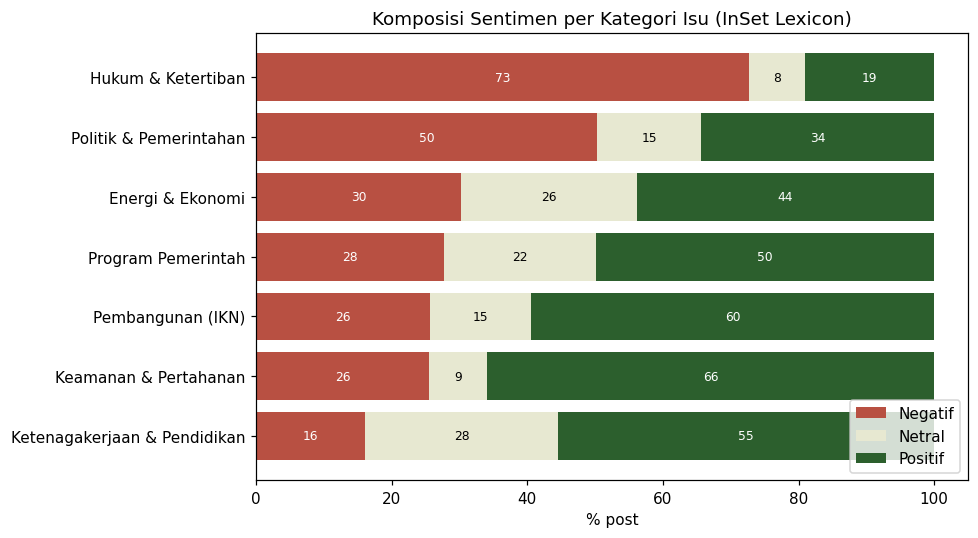

In [27]:
neg = sent_topic['Negatif'].values
net = sent_topic['Netral'].values
pos = sent_topic['Positif'].values
categories = sent_topic.index
y = np.arange(len(categories))

fig, ax = plt.subplots(figsize=(9,5))
ax.barh(y, neg, color='#B85042', label='Negatif')
ax.barh(y, net, left=neg, color='#E7E8D1', label='Netral')
ax.barh(y, pos, left=neg + net, color='#2C5F2D', label='Positif')

# label persentase di tengah tiap segmen (dilewati jika segmen terlalu kecil supaya tidak tumpang tindih)
for i in range(len(categories)):
    if neg[i] > 4:
        ax.text(neg[i]/2, y[i], f'{neg[i]:.0f}', ha='center', va='center', fontsize=8, color='white')
    if net[i] > 4:
        ax.text(neg[i] + net[i]/2, y[i], f'{net[i]:.0f}', ha='center', va='center', fontsize=8)
    if pos[i] > 4:
        ax.text(neg[i] + net[i] + pos[i]/2, y[i], f'{pos[i]:.0f}', ha='center', va='center', fontsize=8, color='white')

ax.set_yticks(y)
ax.set_yticklabels(categories)
ax.set_xlabel('% post')
ax.set_title('Komposisi Sentimen per Kategori Isu (InSet Lexicon)')
ax.invert_yaxis()
ax.legend(loc='lower right')
plt.tight_layout()
plt.savefig('chart_sentiment.png', bbox_inches='tight')
plt.show()